In [1]:
import random
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

In [2]:

G = nx.read_edgelist(r"data\facebook_combined.txt", nodetype=int)
adj_list = {node: list(G.neighbors(node)) for node in G.nodes()}
all_nodes = list(G.nodes())


def run_single_simulation(
    adj_list, all_nodes, beta=0.05, gamma=0.2, initial_spreaders=5, immunized=None):
    """
    Simulates a single run of fake news spreading.
    beta  - chance (0..1) that a friend believes and shares the post in a given step
    gamma - chance (0..1) that a sharer gets bored or sees a fact
    immunized - set of IDs that are protected from the start (won't share further)
    """
    if immunized is None:
        immunized = set()

    # pacient zero - first spreaders, randomly chosen from the non-immunized population
    available_nodes = [n for n in all_nodes if n not in immunized]
    spreaders = set(random.sample(available_nodes, initial_spreaders))
    stiflers = set(immunized)

    history_spreaders = [len(spreaders)]
    total_believed = len(spreaders)

    # loop until there are no more spreaders
    while spreaders:
        new_spreaders = set()
        new_stiflers = set()

        for user in spreaders:
            # try to spread the fake news to friends
            for friend in adj_list[user]:
                if (
                    friend not in spreaders
                    and friend not in stiflers
                    and friend not in new_spreaders
                ):
                    if random.random() < beta:
                        new_spreaders.add(friend)

            # check if the current spreader becomes a stifler (loses interest)
            if random.random() < gamma:
                new_stiflers.add(user)

        spreaders = (spreaders - new_stiflers) | new_spreaders
        stiflers = stiflers | new_stiflers
        total_believed += len(new_spreaders)
        history_spreaders.append(len(spreaders))

    return {
        "total_reached": total_believed,
        "pct_reached": (total_believed / len(all_nodes)) * 100,
        "peak_spreaders": max(history_spreaders),
        "duration": len(history_spreaders),
        "curve": history_spreaders,
    }


In [11]:
result = run_single_simulation(adj_list, all_nodes, beta=0.05, gamma=0.2)
print(f"Fake news reached: {result['total_reached']} people ({result['pct_reached']:.1f}% network)")
print(f"In peak: {result['peak_spreaders']} people")
print(f"Duration of the wave: {result['duration']} steps")

Fake news reached: 3555 people (88.0% network)
In peak: 1403 people
Duration of the wave: 63 steps


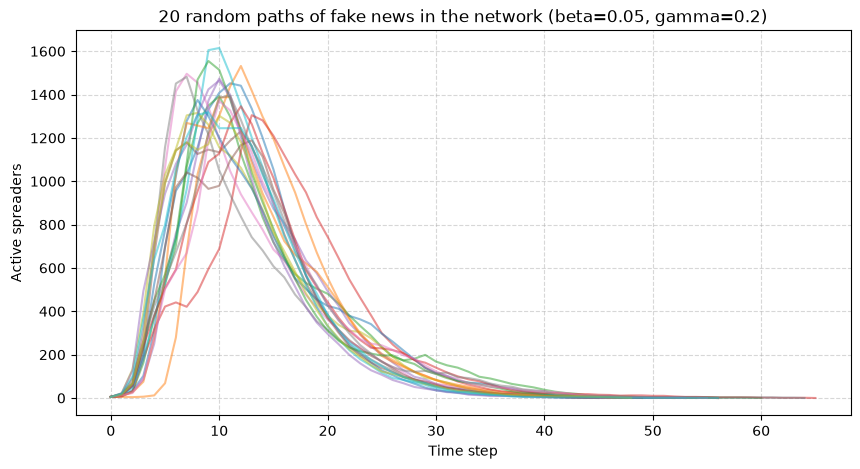

In [12]:
plt.figure(figsize=(10, 5))

for i in range(20):
    res = run_single_simulation(adj_list, all_nodes, beta=0.05, gamma=0.2)
    plt.plot(res["curve"], alpha=0.5, linewidth=1.5)

plt.title("20 random paths of fake news in the network (beta=0.05, gamma=0.2)")
plt.xlabel("Time step")
plt.ylabel("Active spreaders")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()